# Exercise 44 – Fitting models with PyTorch

**Week 8 · Automatic differentiation**

Autograd gives us gradients of a loss with respect to model parameters, so
fitting becomes gradient descent. We first look at derivatives at data points,
then fit three different models (parabola, Gaussian, circle) to the same three
points by wrapping the parameters in a `torch.nn.Module`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn

from comphy.plotting import annotate, setup_axes
from comphy.training import fit

torch.manual_seed(0);

## Derivative at data points

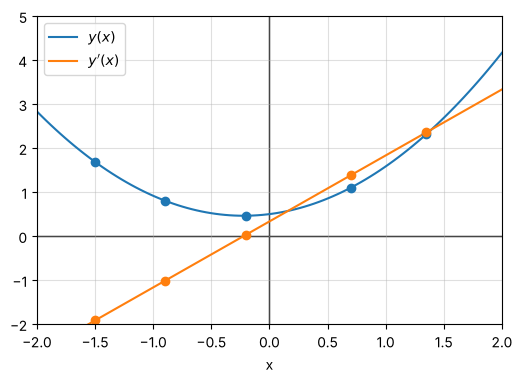

In [2]:
def f(x):
    return 0.75 * x**2 + x / 3 + 0.5


xs = torch.linspace(-2, 2, 100, requires_grad=True)
dfdx = torch.autograd.grad(f(xs), xs, torch.ones_like(xs))[0]

points = torch.tensor([-1.5, -0.9, -0.2, 0.7, 1.35], requires_grad=True)
slopes = torch.autograd.grad(f(points), points, torch.ones_like(points))[0]

fig, ax = plt.subplots(figsize=(6, 4))
with torch.no_grad():
    ax.plot(xs, f(xs), label="$y(x)$")
    ax.plot(xs, dfdx, label="$y'(x)$")
    ax.plot(points, f(points), "o", color="C0")
    ax.plot(points, slopes, "o", color="C1")
setup_axes(ax, xlim=(-2, 2), ylim=(-2, 5), ylabel="")
ax.legend()
plt.show()

## Three models for the same three points

Each model is a `nn.Module` whose parameters are `nn.Parameter`s, so that
`model.parameters()` can be handed to the optimiser.

In [3]:
data = torch.tensor([[1.0, 2.0], [3.0, 4.0], [5.0, 1.0]])
x_data, y_data = data[:, 0], data[:, 1]


class Parabola(nn.Module):
    def __init__(self):
        super().__init__()
        self.a = nn.Parameter(torch.tensor(0.0))
        self.b = nn.Parameter(torch.tensor(0.0))
        self.c = nn.Parameter(torch.tensor(0.0))

    def forward(self, x):
        return self.a * x**2 + self.b * x + self.c


class Gaussian(nn.Module):
    def __init__(self, A=1.0, x0=1.0, sigma=1.0):
        super().__init__()
        self.A = nn.Parameter(torch.tensor(A))
        self.x0 = nn.Parameter(torch.tensor(x0))
        self.sigma = nn.Parameter(torch.tensor(sigma))

    def forward(self, x):
        return self.A * torch.exp(-((x - self.x0) ** 2) / (2 * self.sigma**2))


class Circle(nn.Module):
    """Returns the distance from the centre; the loss compares it with r."""

    def __init__(self):
        super().__init__()
        self.r = nn.Parameter(torch.tensor(1.0))
        self.centre = nn.Parameter(torch.tensor([1.0, 1.0]))

    def forward(self, points):
        return (points - self.centre).norm(dim=1)

In [4]:
parabola = Parabola()
fit(parabola, x_data, y_data, steps=3500, lr=0.01)

gaussian = Gaussian()
fit(gaussian, x_data, y_data, steps=3500, lr=0.01)

# For the circle all points should lie at distance r from the centre.
circle = Circle()
optimizer = torch.optim.Adam(circle.parameters(), lr=0.01)
for _ in range(3000):
    optimizer.zero_grad()
    loss = (circle(data) - circle.r).abs().mean()
    loss.backward()
    optimizer.step()

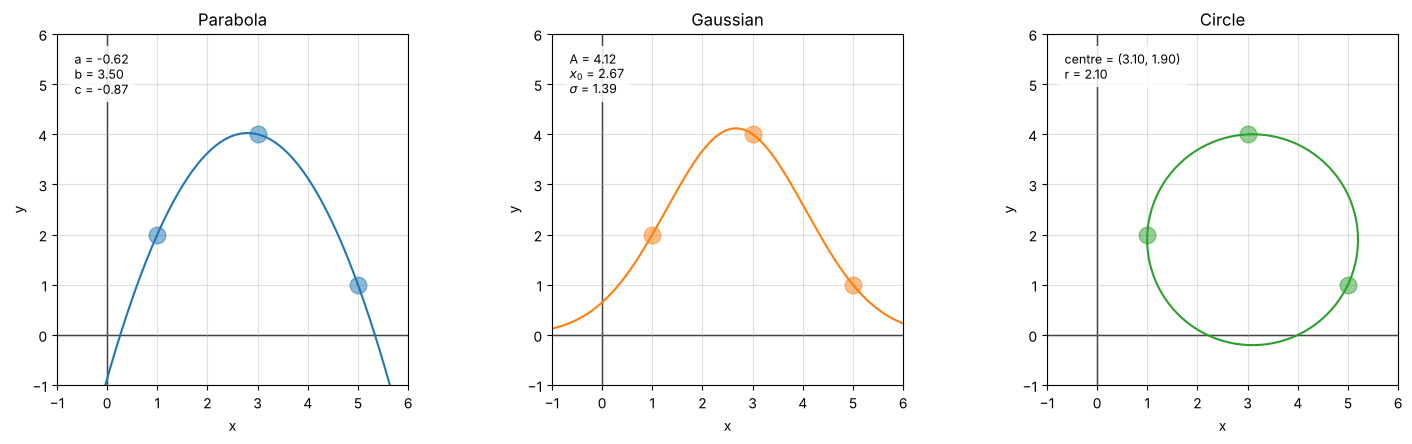

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
xs = torch.linspace(-1, 6, 200)
theta = torch.linspace(0, 2 * np.pi, 200)

with torch.no_grad():
    axes[0].plot(xs, parabola(xs), color="C0")
    annotate(axes[0], f"a = {parabola.a.item():.2f}\nb = {parabola.b.item():.2f}\nc = {parabola.c.item():.2f}")

    axes[1].plot(xs, gaussian(xs), color="C1")
    annotate(axes[1], f"A = {gaussian.A.item():.2f}\n$x_0$ = {gaussian.x0.item():.2f}\n"
                      f"$\\sigma$ = {gaussian.sigma.item():.2f}")

    cx, cy = circle.centre
    axes[2].plot(cx + circle.r * torch.cos(theta), cy + circle.r * torch.sin(theta), color="C2")
    annotate(axes[2], f"centre = ({cx:.2f}, {cy:.2f})\nr = {circle.r.item():.2f}")

for ax, color, title in zip(axes, ["C0", "C1", "C2"], ["Parabola", "Gaussian", "Circle"]):
    ax.plot(x_data, y_data, "o", color=color, markersize=12, alpha=0.5)
    setup_axes(ax, xlim=(-1, 6), ylim=(-1, 6), title=title, equal=True)
fig.tight_layout()
plt.show()